# E03 · 复杂道路车道检测（探索式 Notebook V1.0）
**学生实验：四项核心探索 + 三段真实道路视频。** 先预测、每次只改变一个变量、观察真实图像、解释失败。  
本 Notebook 不依赖 GPU 或模型训练。所有拟合都是未标注的几何候选，不是人工 Ground Truth。

## 00 · 环境和真实视频素材
直道、普通弯道、复杂连续弯道素材均来自 Udacity CarND 项目；原始文件有 SHA256 校验。

In [1]:
from pathlib import Path
import cv2, numpy as np, matplotlib.pyplot as plt
from IPython.display import display, Video
from zipfile import ZipFile
# Local WSL/Jupyter/VS Code and Kaggle dataset layout.
def locate_e03():
    base=Path.cwd()
    for root in (base,base.parent,Path('/kaggle/input')):
        if not root.exists(): continue
        if (root/'images/01_solidWhiteRight_straight_white.jpg').is_file() and (root/'videos/E03_straight_input.mp4').is_file():return root
        if root == Path('/kaggle/input'):
            for file in root.glob('**/videos/E03_straight_input.mp4'):
                maybe=file.parent.parent
                if (maybe/'images/01_solidWhiteRight_straight_white.jpg').exists():return maybe
    raise FileNotFoundError('请完整解压 MVAI_E03_Lab.zip，确保 images/ 与 videos/ 位于 Notebook 同级')
DATA=locate_e03()
OUTPUT=Path.cwd()/'e03_outputs';OUTPUT.mkdir(exist_ok=True)
def read_image(name):
    img=cv2.imread(str(DATA/'images'/name))
    if img is None:raise FileNotFoundError(name)
    return cv2.resize(img,(640,360))
def panels(items,cols=3,size=(5,3)):
    rows=(len(items)+cols-1)//cols
    fig,axes=plt.subplots(rows,cols,figsize=(cols*size[0],rows*size[1]))
    for ax in np.atleast_1d(axes).ravel():ax.axis('off')
    for ax,(title,img) in zip(np.atleast_1d(axes).ravel(),items):
        ax.imshow(img if img.ndim==2 else cv2.cvtColor(img,cv2.COLOR_BGR2RGB));ax.set_title(title,fontsize=11);ax.axis('off')
    plt.tight_layout();plt.show()
print('E03 DATA:',DATA,'OpenCV',cv2.__version__)

E03 DATA: /home/runner/work/multimodal-document-ai-learning-center/multimodal-document-ai-learning-center/docs/resources/course-labs/intelligent-perception OpenCV 5.1.0


In [2]:
"""E03 classroom-only classical lane-finding kernel, CPU/OpenCV; no learned model.
Returned lane curves are unlabelled geometry hypotheses, not ground truth.
"""
import cv2
import numpy as np
from dataclasses import dataclass

# Camera-dependent approximate road quadrilaterals; not physical calibration.
SCENE_QUADS = {
    'straight': (.43, .59, .09, .94, .60),
    'curve': (.42, .63, .06, .96, .61),
    'complex': (.40, .63, .03, .95, .61),
}

def resized(frame, size=(640, 360)):
    return cv2.resize(frame, size, interpolation=cv2.INTER_AREA)

def perspective(frame, scene='curve', top_shift=0., width_shift=0.):
    h,w=frame.shape[:2]
    left_top,right_top,left_bottom,right_bottom,y_top=SCENE_QUADS.get(scene,SCENE_QUADS['curve'])
    y_top=float(np.clip(y_top+top_shift,.42,.72))
    span=(right_top-left_top)*float(np.clip(1.+width_shift,.6,1.5))
    cx=(left_top+right_top)/2
    src=np.float32([[(cx-span/2)*w,y_top*h],[(cx+span/2)*w,y_top*h],
                    [right_bottom*w,.98*h],[left_bottom*w,.98*h]])
    dst=np.float32([[.23*w,0],[.77*w,0],[.77*w,h-1],[.23*w,h-1]])
    M=cv2.getPerspectiveTransform(src,dst)
    Minv=cv2.getPerspectiveTransform(dst,src)
    warped=cv2.warpPerspective(frame,M,(w,h))
    return warped,M,Minv,src

def e02_hough(frame, lo=50,hi=150,votes=25,length=35,gap=70,top=.55):
    """Reference to the approved E02 per-frame Canny→ROI→HoughLinesP route."""
    h,w=frame.shape[:2]
    gray=cv2.cvtColor(frame,cv2.COLOR_BGR2GRAY)
    edges=cv2.Canny(cv2.GaussianBlur(gray,(5,5),1.2),lo,hi)
    mask=np.zeros_like(edges)
    poly=np.array([[(int(.05*w),int(.97*h)),(int(.42*w),int(top*h)),
                    (int(.58*w),int(top*h)),(int(.98*w),int(.97*h))]],np.int32)
    cv2.fillPoly(mask,poly,255)
    roi=cv2.bitwise_and(edges,mask)
    lines=cv2.HoughLinesP(roi,1,np.pi/180,threshold=votes,minLineLength=length,maxLineGap=gap)
    out=frame.copy()
    found=[] if lines is None else np.asarray(lines).reshape(-1,4).tolist()
    for x1,y1,x2,y2 in found:
        cv2.line(out,(x1,y1),(x2,y2),(30,220,30),2)
    return out,len(found),roi

def lane_masks(bgr,l_min=200,s_min=130,grad_min=45,clahe=False):
    if clahe:
        lab=cv2.cvtColor(bgr,cv2.COLOR_BGR2LAB)
        lab[:,:,0]=cv2.createCLAHE(clipLimit=2.0,tileGridSize=(8,8)).apply(lab[:,:,0])
        bgr=cv2.cvtColor(lab,cv2.COLOR_LAB2BGR)
    hls=cv2.cvtColor(bgr,cv2.COLOR_BGR2HLS)
    h,l,s=cv2.split(hls)
    white=(l>=l_min)&(s<=175)
    yellow=(h>=12)&(h<=45)&(s>=s_min)&(l>=60)
    gx=cv2.Sobel(l,cv2.CV_32F,1,0,ksize=3)
    gx=cv2.convertScaleAbs(gx)
    gradient=(gx>=grad_min)&(l>=90)
    combo=((white|yellow)|(gradient & (l>115))).astype(np.uint8)*255
    k=cv2.getStructuringElement(cv2.MORPH_RECT,(3,3))
    combo=cv2.morphologyEx(combo,cv2.MORPH_CLOSE,k)
    return (white.astype(np.uint8)*255,yellow.astype(np.uint8)*255,
            gradient.astype(np.uint8)*255,combo)

def sliding_window(binary,nwindows=9,margin_frac=.10,minpix=35):
    h,w=binary.shape
    hist=np.sum((binary[h//2:]>0).astype(np.int32),axis=0)
    mid=w//2
    # Localize left and right within their respective halves; no semantic promise.
    left=int(np.argmax(hist[int(.05*w):mid])+int(.05*w))
    right=int(np.argmax(hist[mid:int(.95*w)])+mid)
    nony,nonx=np.nonzero(binary)
    width=max(1,h//int(nwindows))
    margin=max(8,int(margin_frac*w))
    left_ids=[];right_ids=[];boxes=[]
    for k in range(int(nwindows)):
        yhi=h-k*width; ylo=max(0,yhi-width)
        for side,center,collect in [('left',left,left_ids),('right',right,right_ids)]:
            xlo=max(0,center-margin);xhi=min(w,center+margin)
            ids=np.where((nony>=ylo)&(nony<yhi)&(nonx>=xlo)&(nonx<xhi))[0]
            collect.extend(ids.tolist())
            boxes.append((xlo,ylo,xhi,yhi,side))
            if len(ids)>minpix:
                if side=='left':left=int(np.mean(nonx[ids]))
                else:right=int(np.mean(nonx[ids]))
    return nonx,nony,np.asarray(left_ids,dtype=int),np.asarray(right_ids,dtype=int),boxes

def fit_lanes(binary,nwindows=9,margin_frac=.10,minpix=35):
    h,w=binary.shape
    xs,ys,left_ids,right_ids,boxes=sliding_window(binary,nwindows,margin_frac,minpix)
    result={'valid':False,'boxes':boxes,'left_pixels':len(left_ids),'right_pixels':len(right_ids)}
    if min(len(left_ids),len(right_ids))<max(60,2*minpix):return result
    if np.ptp(ys[left_ids])<.20*h or np.ptp(ys[right_ids])<.20*h:return result
    # Normalize y to improve polynomial stability.
    try:
        yl=ys[left_ids]/h; yr=ys[right_ids]/h
        lf=np.polyfit(yl,xs[left_ids],2);rf=np.polyfit(yr,xs[right_ids],2)
    except (np.linalg.LinAlgError,ValueError):return result
    probes=np.array([.38,.62,.91])
    lx=np.polyval(lf,probes);rx=np.polyval(rf,probes)
    widths=rx-lx
    # Soft guards are diagnostic: do not fabricate a line from insufficient data.
    if not np.all(np.isfinite(widths)) or not np.all((widths>.12*w)&(widths<.86*w)):
        return result
    result.update(valid=True,left=lf,right=rf,probes=probes,left_x=lx,right_x=rx)
    return result

@dataclass
class LaneTracker:
    alpha:float=.6
    max_missing:int=3
    last:object=None
    missing:int=0

    def update(self,d):
        if d.get('valid'):
            xy=np.stack([d['left_x'],d['right_x']])
            if self.last is not None and self.missing<=self.max_missing:
                # Accept real changes but suppress small instantaneous oscillations.
                xy=self.alpha*xy+(1-self.alpha)*self.last
            self.last=xy;self.missing=0
            return xy,'DETECTED'
        self.missing+=1
        if self.last is not None and self.missing<=self.max_missing:
            return self.last,'HISTORY (unverified)'
        self.last=None
        return None,'NO RELIABLE LANE'

def draw_curve(frame,Minv,fit,tracker=None,alpha=.6):
    out=frame.copy();h,w=frame.shape[:2]
    if tracker is None:tracker=LaneTracker(alpha=alpha,max_missing=0)
    xy,status=tracker.update(fit)
    if xy is None:
        cv2.putText(out,status,(12,30),cv2.FONT_HERSHEY_SIMPLEX,.65,(25,25,235),2)
        return out,status,None
    # Reconstruct a quadratic from 3 normalized-y probe positions per boundary.
    y=fit.get('probes',np.array([.38,.62,.91]))
    lc=np.polyfit(y,xy[0],2);rc=np.polyfit(y,xy[1],2)
    yt=np.linspace(.32,.98,50)
    left=np.column_stack([np.polyval(lc,yt),yt*h]).astype(np.float32)
    right=np.column_stack([np.polyval(rc,yt),yt*h]).astype(np.float32)
    polygon=np.concatenate([left,right[::-1]])
    warped_poly=cv2.perspectiveTransform(polygon.reshape(-1,1,2),Minv).reshape(-1,2)
    pts=np.round(warped_poly).astype(np.int32)
    mask=np.zeros_like(out);cv2.fillPoly(mask,[pts],(55,180,35))
    out=cv2.addWeighted(out,1.,mask,.23,0)
    borders=cv2.perspectiveTransform(np.stack([left,right]).reshape(-1,1,2),Minv).reshape(2,-1,2)
    for line,color in zip(borders,[(255,170,20),(20,220,255)]):
        cv2.polylines(out,[np.round(line).astype(np.int32)],False,color,4,cv2.LINE_AA)
    cv2.putText(out,status,(12,30),cv2.FONT_HERSHEY_SIMPLEX,.54,(255,255,255),2)
    return out,status,float(np.mean(xy[:,2]))

def e03_detect(frame,scene='curve',tracker=None,top_shift=0.,width_shift=0.,
               nwindows=9,margin_frac=.10,l_min=200,s_min=130,clahe=False):
    bird,M,Minv,src=perspective(frame,scene,top_shift,width_shift)
    wm,ym,gm,binary=lane_masks(bird,l_min,s_min,clahe=clahe)
    h,w=binary.shape
    binary[:int(.08*h)]=0
    fit=fit_lanes(binary,nwindows,margin_frac)
    overlay,status,bottom=draw_curve(frame,Minv,fit,tracker)
    fit['status']=status;fit['bottom_x']=bottom
    return overlay,fit,{'bird':bird,'mask':binary,'white':wm,'yellow':ym,'grad':gm,'src':src}

## 01 · 探索一：道路透视与鸟瞰变换
**先预测：** 改变透视梯形顶部高度，会保留更多道路还是引入更多非车道区域？
1. 固定顶边宽度，仅比较顶边高度比例 0.50 / 0.56 / 0.62。
2. 固定高度，再比较顶边宽度；换到急弯观察裁剪失效。
3. 思考：鸟瞰图是否等于经过相机标定的真实地面几何？

/tmp/ipykernel_2887/2224602797.py:28: UserWarning: Glyph 30495 (\N{CJK UNIFIED IDEOGRAPH-771F}) missing from font(s) DejaVu Sans.
  plt.tight_layout();plt.show()
/tmp/ipykernel_2887/2224602797.py:28: UserWarning: Glyph 23454 (\N{CJK UNIFIED IDEOGRAPH-5B9E}) missing from font(s) DejaVu Sans.
  plt.tight_layout();plt.show()
/tmp/ipykernel_2887/2224602797.py:28: UserWarning: Glyph 36947 (\N{CJK UNIFIED IDEOGRAPH-9053}) missing from font(s) DejaVu Sans.
  plt.tight_layout();plt.show()
/tmp/ipykernel_2887/2224602797.py:28: UserWarning: Glyph 36335 (\N{CJK UNIFIED IDEOGRAPH-8DEF}) missing from font(s) DejaVu Sans.
  plt.tight_layout();plt.show()
/tmp/ipykernel_2887/2224602797.py:28: UserWarning: Glyph 39030 (\N{CJK UNIFIED IDEOGRAPH-9876}) missing from font(s) DejaVu Sans.
  plt.tight_layout();plt.show()
/tmp/ipykernel_2887/2224602797.py:28: UserWarning: Glyph 36793 (\N{CJK UNIFIED IDEOGRAPH-8FB9}) missing from font(s) DejaVu Sans.
  plt.tight_layout();plt.show()
/tmp/ipykernel_2887/22246027

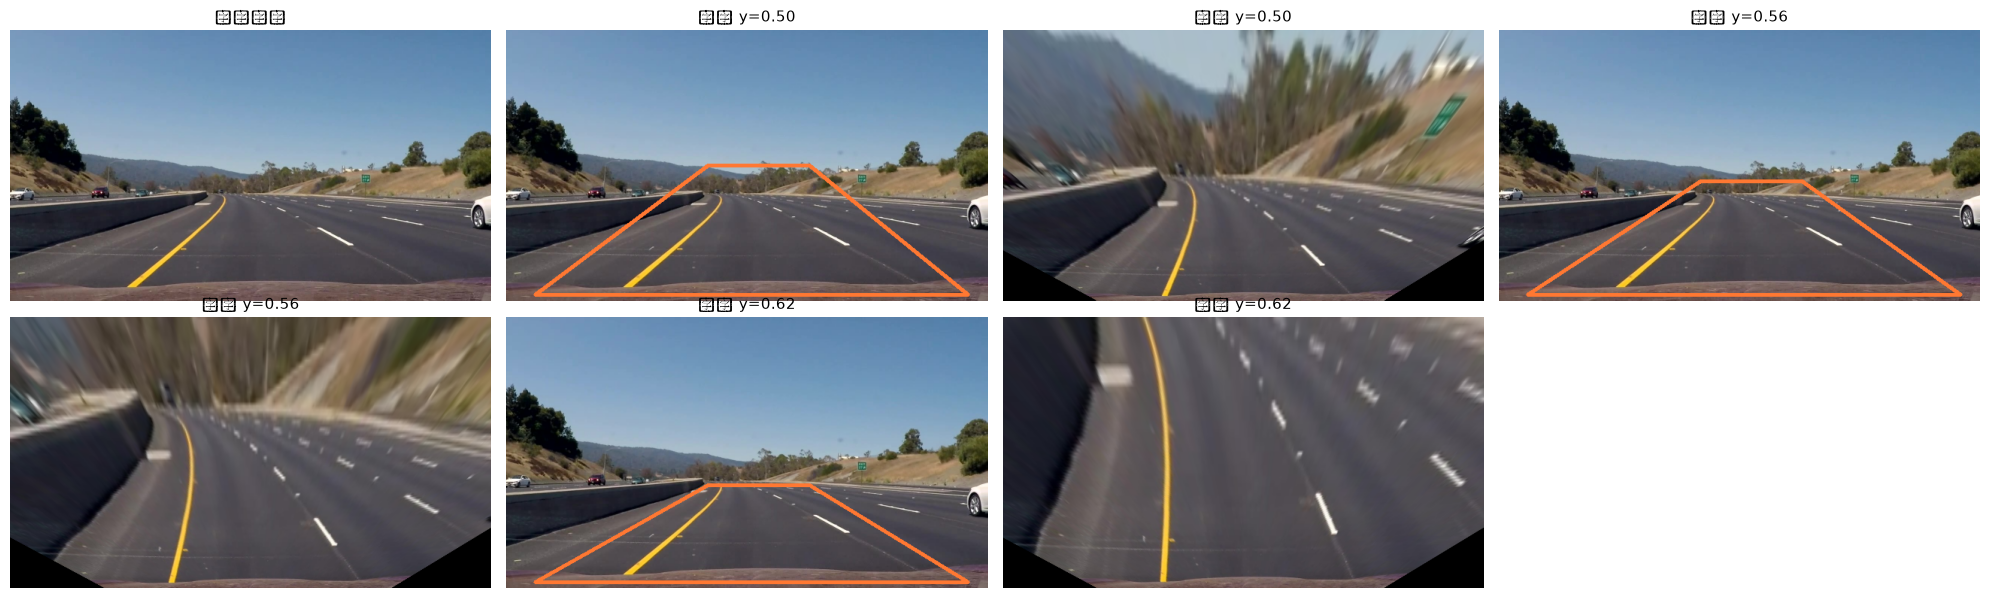

In [3]:
img=read_image('03_project_curve_intro.jpg')
results=[('真实道路',img)]
for shift in (-.11,-.05,.01):
    bird,M,Minv,src=perspective(img,'curve',top_shift=shift)
    draw=img.copy();cv2.polylines(draw,[np.int32(src)],True,(50,120,255),3)
    results.extend([(f'顶边 y={.61+shift:.2f}',draw),(f'鸟瞰 y={.61+shift:.2f}',bird)])
panels(results,cols=4)

/tmp/ipykernel_2887/2224602797.py:28: UserWarning: Glyph 22797 (\N{CJK UNIFIED IDEOGRAPH-590D}) missing from font(s) DejaVu Sans.
  plt.tight_layout();plt.show()
/tmp/ipykernel_2887/2224602797.py:28: UserWarning: Glyph 26434 (\N{CJK UNIFIED IDEOGRAPH-6742}) missing from font(s) DejaVu Sans.
  plt.tight_layout();plt.show()
/tmp/ipykernel_2887/2224602797.py:28: UserWarning: Glyph 24367 (\N{CJK UNIFIED IDEOGRAPH-5F2F}) missing from font(s) DejaVu Sans.
  plt.tight_layout();plt.show()
/tmp/ipykernel_2887/2224602797.py:28: UserWarning: Glyph 36947 (\N{CJK UNIFIED IDEOGRAPH-9053}) missing from font(s) DejaVu Sans.
  plt.tight_layout();plt.show()
/tmp/ipykernel_2887/2224602797.py:28: UserWarning: Glyph 21407 (\N{CJK UNIFIED IDEOGRAPH-539F}) missing from font(s) DejaVu Sans.
  plt.tight_layout();plt.show()
/tmp/ipykernel_2887/2224602797.py:28: UserWarning: Glyph 22270 (\N{CJK UNIFIED IDEOGRAPH-56FE}) missing from font(s) DejaVu Sans.
  plt.tight_layout();plt.show()
/tmp/ipykernel_2887/22246027

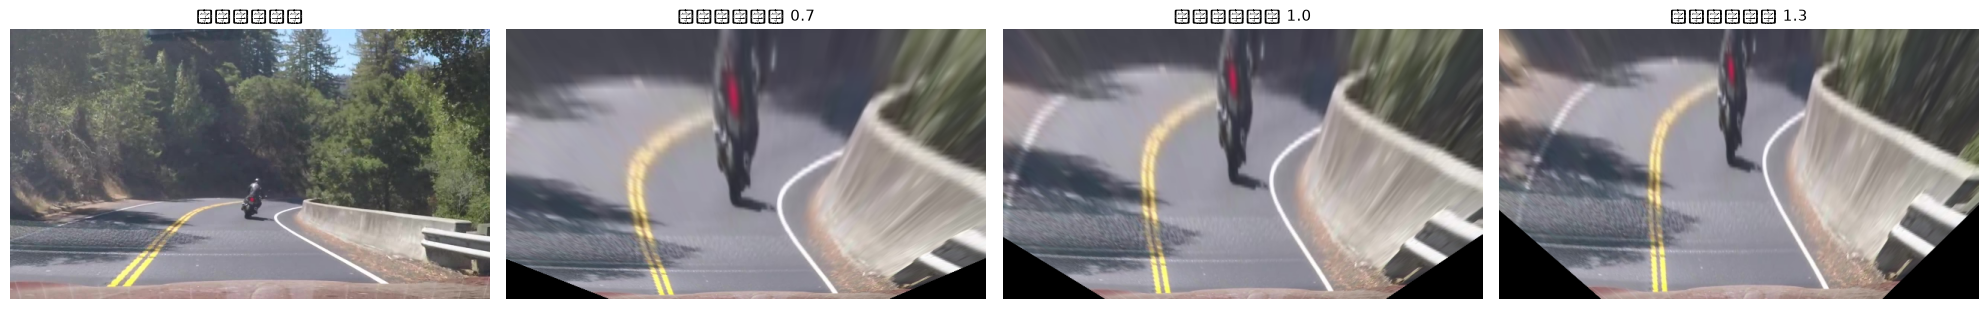

In [4]:
img=read_image('07_harder_curve_motorcycle.jpg')
panels([('复杂弯道原图',img)]+[(f'顶边宽度倍率 {1+x:.1f}',perspective(img,'complex',width_shift=x)[0]) for x in (-.3,0,.3)],cols=4)

## 02 · 探索二：从 Hough 直线到曲线拟合
**先预测：** 将滑动窗口加宽，能否避免急弯漏检？会不会同时抓到护栏和阴影？
1. 对比 E02 Hough、鸟瞰掩膜、滑动窗口与二次曲线。
2. 只修改窗口数量 6 / 9 / 12，比较候选像素和有效性。
3. 解释二次曲线、分段曲线与连续 S 形转向的关系；拟合平滑不代表检测正确。

/tmp/ipykernel_2887/2224602797.py:28: UserWarning: Glyph 21407 (\N{CJK UNIFIED IDEOGRAPH-539F}) missing from font(s) DejaVu Sans.
  plt.tight_layout();plt.show()
/tmp/ipykernel_2887/2224602797.py:28: UserWarning: Glyph 22270 (\N{CJK UNIFIED IDEOGRAPH-56FE}) missing from font(s) DejaVu Sans.
  plt.tight_layout();plt.show()
/tmp/ipykernel_2887/2224602797.py:28: UserWarning: Glyph 20505 (\N{CJK UNIFIED IDEOGRAPH-5019}) missing from font(s) DejaVu Sans.
  plt.tight_layout();plt.show()
/tmp/ipykernel_2887/2224602797.py:28: UserWarning: Glyph 36873 (\N{CJK UNIFIED IDEOGRAPH-9009}) missing from font(s) DejaVu Sans.
  plt.tight_layout();plt.show()
/tmp/ipykernel_2887/2224602797.py:28: UserWarning: Glyph 40479 (\N{CJK UNIFIED IDEOGRAPH-9E1F}) missing from font(s) DejaVu Sans.
  plt.tight_layout();plt.show()
/tmp/ipykernel_2887/2224602797.py:28: UserWarning: Glyph 30640 (\N{CJK UNIFIED IDEOGRAPH-77B0}) missing from font(s) DejaVu Sans.
  plt.tight_layout();plt.show()
/tmp/ipykernel_2887/22246027

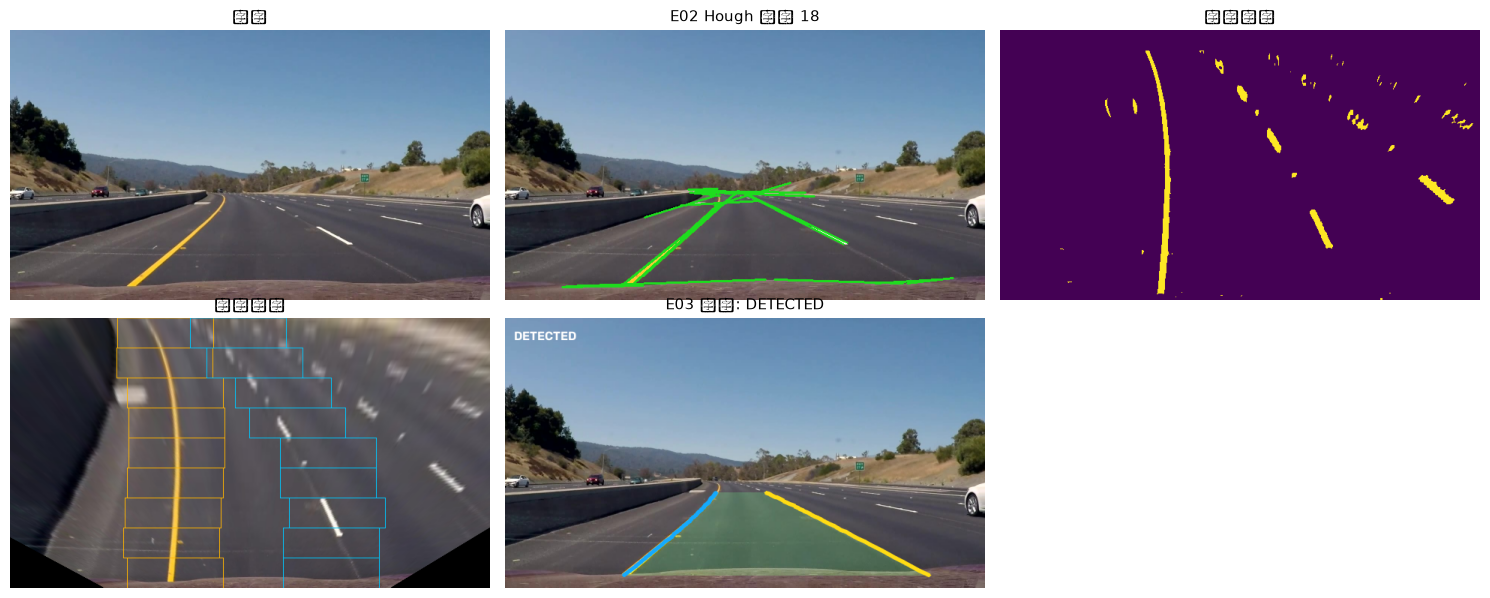

候选像素 (左/右): 2445 1174 拟合有效: True


In [5]:
img=read_image('03_project_curve_intro.jpg')
e02,n,roi=e02_hough(img)
e03,fit,steps=e03_detect(img,'curve')
search=steps['bird'].copy()
for x1,y1,x2,y2,side in fit['boxes']:
    cv2.rectangle(search,(x1,y1),(x2,y2),(0,180,255) if side=='left' else (255,200,0),1)
panels([('原图',img),(f'E02 Hough 候选 {n}',e02),('鸟瞰掩膜',steps['mask']),('滑动窗口',search),(f'E03 曲线: {fit["status"]}',e03)],cols=3)
print('候选像素 (左/右):',fit['left_pixels'],fit['right_pixels'],'拟合有效:',fit['valid'])

/tmp/ipykernel_2887/2224602797.py:28: UserWarning: Glyph 22797 (\N{CJK UNIFIED IDEOGRAPH-590D}) missing from font(s) DejaVu Sans.
  plt.tight_layout();plt.show()
/tmp/ipykernel_2887/2224602797.py:28: UserWarning: Glyph 26434 (\N{CJK UNIFIED IDEOGRAPH-6742}) missing from font(s) DejaVu Sans.
  plt.tight_layout();plt.show()
/tmp/ipykernel_2887/2224602797.py:28: UserWarning: Glyph 24367 (\N{CJK UNIFIED IDEOGRAPH-5F2F}) missing from font(s) DejaVu Sans.
  plt.tight_layout();plt.show()
/tmp/ipykernel_2887/2224602797.py:28: UserWarning: Glyph 36947 (\N{CJK UNIFIED IDEOGRAPH-9053}) missing from font(s) DejaVu Sans.
  plt.tight_layout();plt.show()
/tmp/ipykernel_2887/2224602797.py:28: UserWarning: Glyph 21407 (\N{CJK UNIFIED IDEOGRAPH-539F}) missing from font(s) DejaVu Sans.
  plt.tight_layout();plt.show()
/tmp/ipykernel_2887/2224602797.py:28: UserWarning: Glyph 22270 (\N{CJK UNIFIED IDEOGRAPH-56FE}) missing from font(s) DejaVu Sans.
  plt.tight_layout();plt.show()
/tmp/ipykernel_2887/22246027

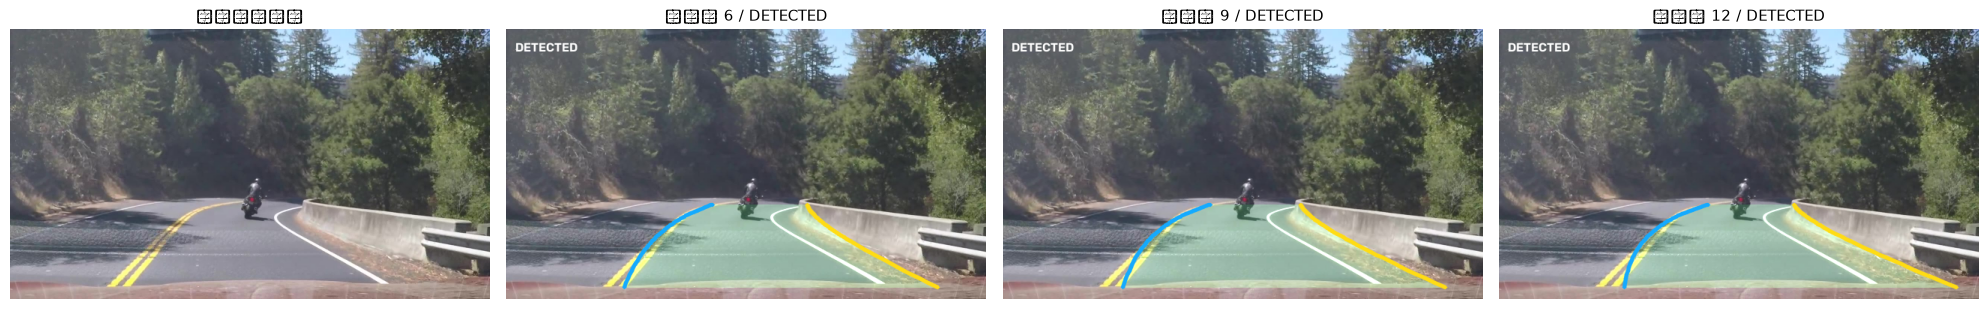

In [6]:
img=read_image('07_harder_curve_motorcycle.jpg')
results=[('复杂弯道原图',img)]
for nw in (6,9,12):
    out,fit,_=e03_detect(img,'complex',nwindows=nw)
    results.append((f'窗口数 {nw} / {fit["status"]}',out))
panels(results,cols=4)

## 03 · 探索三：阴影、强光与标线提取
**先预测：** 降低亮度阈值一定能找回阴影里的白线吗？
1. 在同一图上仅修改 HLS 白线亮度阈值 170 / 200 / 230。
2. 比较黄色掩膜、Sobel 梯度和组合掩膜；观察树影和路面反光。
3. 尝试 CLAHE，讨论增加纹理噪声的副作用。

/tmp/ipykernel_2887/2224602797.py:28: UserWarning: Glyph 24378 (\N{CJK UNIFIED IDEOGRAPH-5F3A}) missing from font(s) DejaVu Sans.
  plt.tight_layout();plt.show()
/tmp/ipykernel_2887/2224602797.py:28: UserWarning: Glyph 20809 (\N{CJK UNIFIED IDEOGRAPH-5149}) missing from font(s) DejaVu Sans.
  plt.tight_layout();plt.show()
/tmp/ipykernel_2887/2224602797.py:28: UserWarning: Glyph 26641 (\N{CJK UNIFIED IDEOGRAPH-6811}) missing from font(s) DejaVu Sans.
  plt.tight_layout();plt.show()
/tmp/ipykernel_2887/2224602797.py:28: UserWarning: Glyph 24433 (\N{CJK UNIFIED IDEOGRAPH-5F71}) missing from font(s) DejaVu Sans.
  plt.tight_layout();plt.show()
/tmp/ipykernel_2887/2224602797.py:28: UserWarning: Glyph 21407 (\N{CJK UNIFIED IDEOGRAPH-539F}) missing from font(s) DejaVu Sans.
  plt.tight_layout();plt.show()
/tmp/ipykernel_2887/2224602797.py:28: UserWarning: Glyph 22270 (\N{CJK UNIFIED IDEOGRAPH-56FE}) missing from font(s) DejaVu Sans.
  plt.tight_layout();plt.show()
/tmp/ipykernel_2887/22246027

/opt/hostedtoolcache/Python/3.11.18/x64/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 30333 (\N{CJK UNIFIED IDEOGRAPH-767D}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/hostedtoolcache/Python/3.11.18/x64/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 40644 (\N{CJK UNIFIED IDEOGRAPH-9EC4}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/hostedtoolcache/Python/3.11.18/x64/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 26799 (\N{CJK UNIFIED IDEOGRAPH-68AF}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


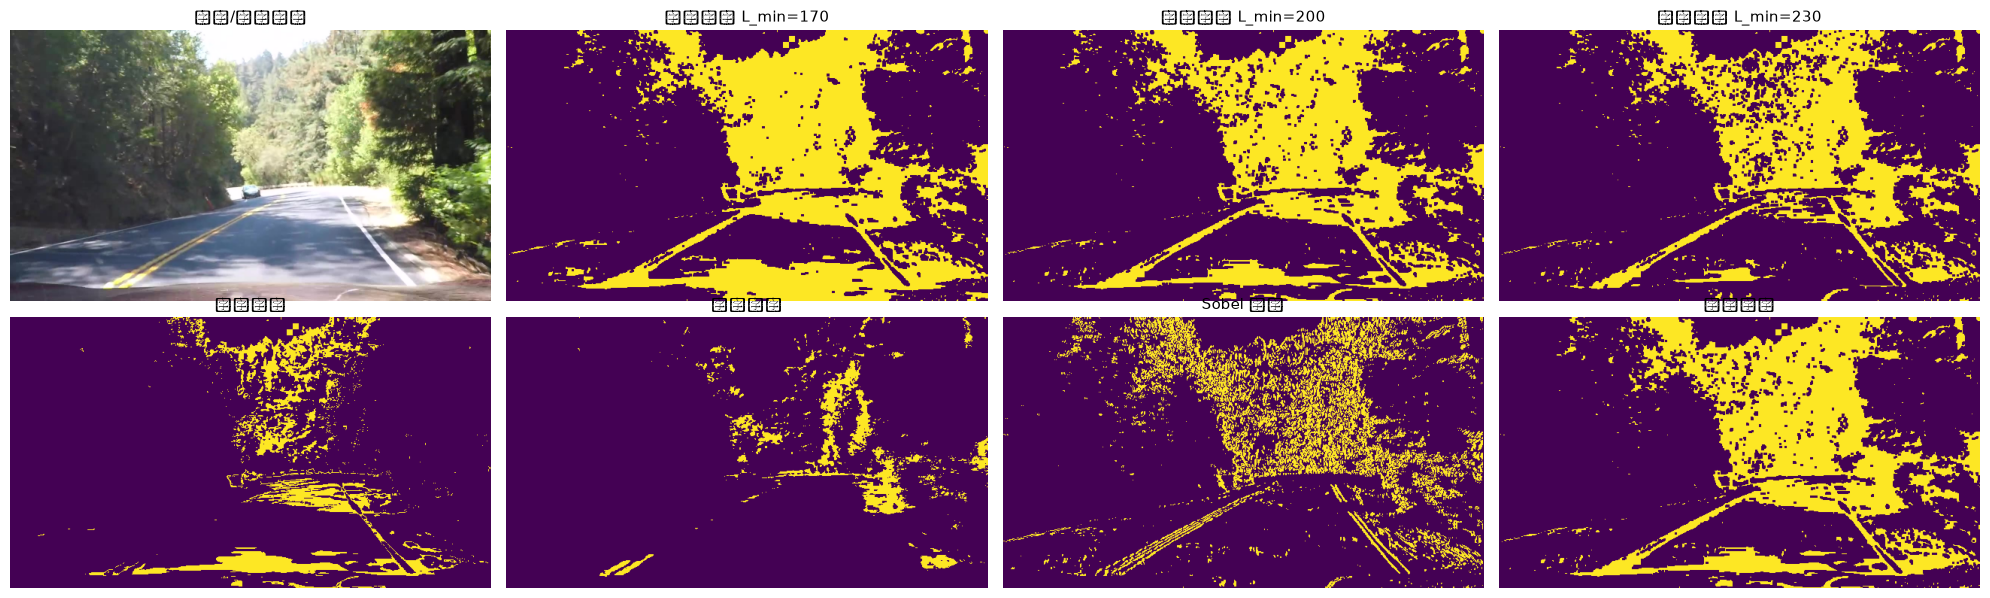

In [7]:
img=read_image('08_harder_shadow_glare.jpg')
results=[('强光/树影原图',img)]
for lum in (170,200,230):
    wm,ym,gm,combo=lane_masks(img,l_min=lum)
    results.append((f'组合掩膜 L_min={lum}',combo))
wm,ym,gm,combo=lane_masks(img,l_min=200)
results.extend([('白线候选',wm),('黄线候选',ym),('Sobel 梯度',gm),('组合掩膜',combo)])
panels(results,cols=4)

/tmp/ipykernel_2887/2224602797.py:28: UserWarning: Glyph 26641 (\N{CJK UNIFIED IDEOGRAPH-6811}) missing from font(s) DejaVu Sans.
  plt.tight_layout();plt.show()
/tmp/ipykernel_2887/2224602797.py:28: UserWarning: Glyph 24433 (\N{CJK UNIFIED IDEOGRAPH-5F71}) missing from font(s) DejaVu Sans.
  plt.tight_layout();plt.show()
/tmp/ipykernel_2887/2224602797.py:28: UserWarning: Glyph 22797 (\N{CJK UNIFIED IDEOGRAPH-590D}) missing from font(s) DejaVu Sans.
  plt.tight_layout();plt.show()
/tmp/ipykernel_2887/2224602797.py:28: UserWarning: Glyph 26434 (\N{CJK UNIFIED IDEOGRAPH-6742}) missing from font(s) DejaVu Sans.
  plt.tight_layout();plt.show()
/tmp/ipykernel_2887/2224602797.py:28: UserWarning: Glyph 22330 (\N{CJK UNIFIED IDEOGRAPH-573A}) missing from font(s) DejaVu Sans.
  plt.tight_layout();plt.show()
/tmp/ipykernel_2887/2224602797.py:28: UserWarning: Glyph 26223 (\N{CJK UNIFIED IDEOGRAPH-666F}) missing from font(s) DejaVu Sans.
  plt.tight_layout();plt.show()
/tmp/ipykernel_2887/22246027

/opt/hostedtoolcache/Python/3.11.18/x64/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 22330 (\N{CJK UNIFIED IDEOGRAPH-573A}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/hostedtoolcache/Python/3.11.18/x64/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 26223 (\N{CJK UNIFIED IDEOGRAPH-666F}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/hostedtoolcache/Python/3.11.18/x64/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 26410 (\N{CJK UNIFIED IDEOGRAPH-672A}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/hostedtoolcache/Python/3.11.18/x64/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 22686 (\N{CJK UNIFIED IDEOGRAPH-589E}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


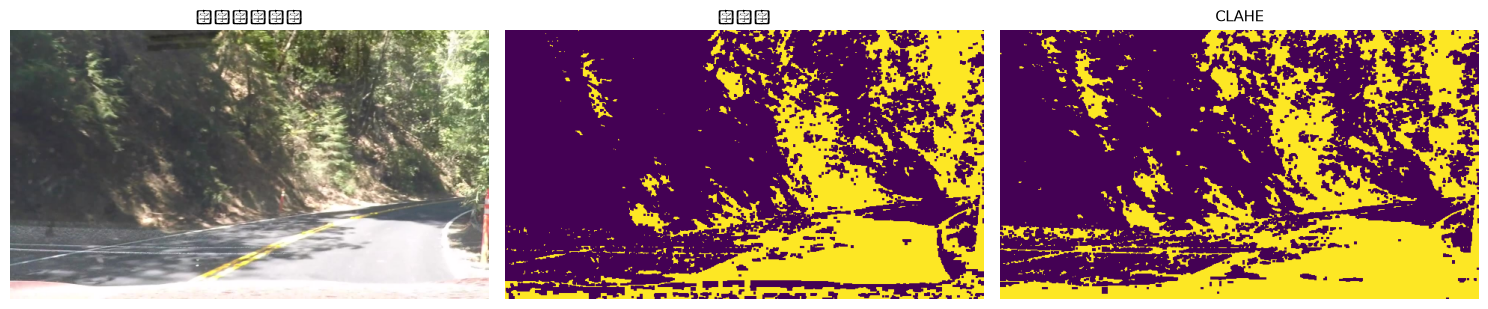

In [8]:
img=read_image('09_harder_curve_shadow.jpg')
base=lane_masks(img,clahe=False)[-1]
strong=lane_masks(img,clahe=True)[-1]
panels([('树影复杂场景',img),('未增强',base),('CLAHE',strong)],cols=3)

## 04 · 探索四：连续帧、时序稳定性与延迟
**先预测：** EMA 系数越小，车道曲线是否总是更准确？
1. 比较 α=1.00、0.60、0.25 对同一帧序列的位置变化。
2. 分析拟合失效时，为什么不能永远沿用上一帧。
3. 区分“位置变化波动”与“有 Ground Truth 的准确率”。

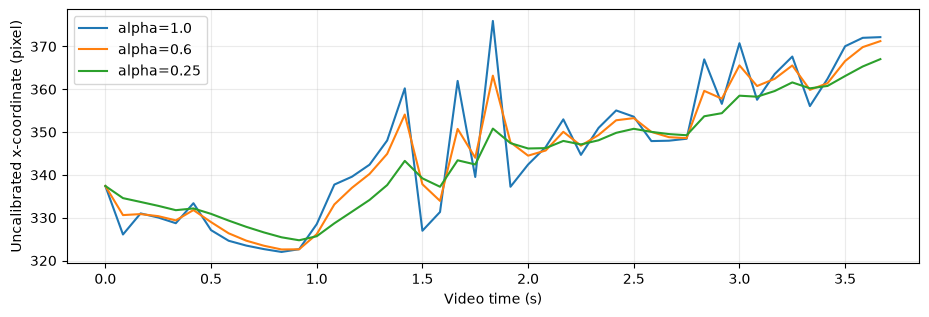

仅为检测输出的连续性对照；不是检测准确率。


In [9]:
# 从真实输入视频提取连续帧，用三种 EMA 系数重跑同一算法。
cap=cv2.VideoCapture(str(DATA/'videos/E03_complex_input.mp4'))
frames=[]
while len(frames)<45:
    ok,f=cap.read()
    if not ok:break
    frames.append(f)
cap.release()
series={}
for alpha in (1.,.6,.25):
    track=LaneTracker(alpha=alpha,max_missing=3)
    scores=[]
    for f in frames:
        _,fit,_=e03_detect(f,'complex',tracker=track)
        scores.append(float(fit['bottom_x']) if fit['bottom_x'] is not None else np.nan)
    series[alpha]=scores
plt.figure(figsize=(11,3.3))
for alpha,values in series.items():plt.plot(np.arange(len(values))/12,values,label=f'alpha={alpha}')
plt.xlabel('Video time (s)');plt.ylabel('Uncalibrated x-coordinate (pixel)');plt.legend();plt.grid(alpha=.25);plt.show()
print('仅为检测输出的连续性对照；不是检测准确率。')

## 05 · 三场景综合展示：真实视频 × E02 × E03
三路画面使用相同源帧：**原始视频 / E02 原始 Canny-Hough 候选 / E03 鸟瞰曲线拟合与 EMA**。
直道检测应尽量保持原有能力；弯道关注实际拟合误差；复杂弯道保留检测失败及恢复，不修饰结果。视频会在当前工作目录 `e03_outputs/` 中产生，可用于课堂播放。

直道: 102 frames; valid 102/102; video E03_straight_compare.mp4


/tmp/ipykernel_2887/2224602797.py:28: UserWarning: Glyph 30452 (\N{CJK UNIFIED IDEOGRAPH-76F4}) missing from font(s) DejaVu Sans.
  plt.tight_layout();plt.show()
/tmp/ipykernel_2887/2224602797.py:28: UserWarning: Glyph 36947 (\N{CJK UNIFIED IDEOGRAPH-9053}) missing from font(s) DejaVu Sans.
  plt.tight_layout();plt.show()
/opt/hostedtoolcache/Python/3.11.18/x64/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 30452 (\N{CJK UNIFIED IDEOGRAPH-76F4}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


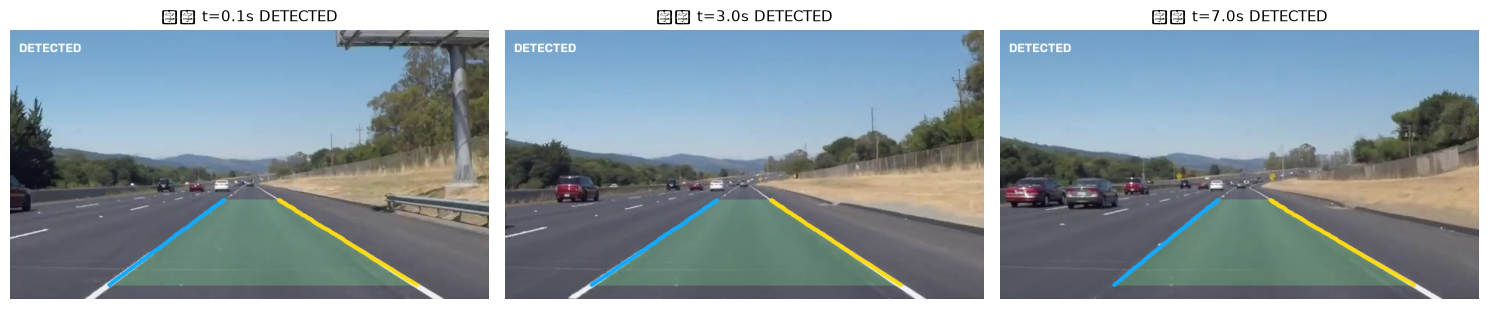

普通弯道: 156 frames; valid 156/156; video E03_curve_compare.mp4


/tmp/ipykernel_2887/2224602797.py:28: UserWarning: Glyph 26222 (\N{CJK UNIFIED IDEOGRAPH-666E}) missing from font(s) DejaVu Sans.
  plt.tight_layout();plt.show()
/tmp/ipykernel_2887/2224602797.py:28: UserWarning: Glyph 36890 (\N{CJK UNIFIED IDEOGRAPH-901A}) missing from font(s) DejaVu Sans.
  plt.tight_layout();plt.show()
/tmp/ipykernel_2887/2224602797.py:28: UserWarning: Glyph 24367 (\N{CJK UNIFIED IDEOGRAPH-5F2F}) missing from font(s) DejaVu Sans.
  plt.tight_layout();plt.show()
/opt/hostedtoolcache/Python/3.11.18/x64/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 26222 (\N{CJK UNIFIED IDEOGRAPH-666E}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/hostedtoolcache/Python/3.11.18/x64/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 36890 (\N{CJK UNIFIED IDEOGRAPH-901A}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


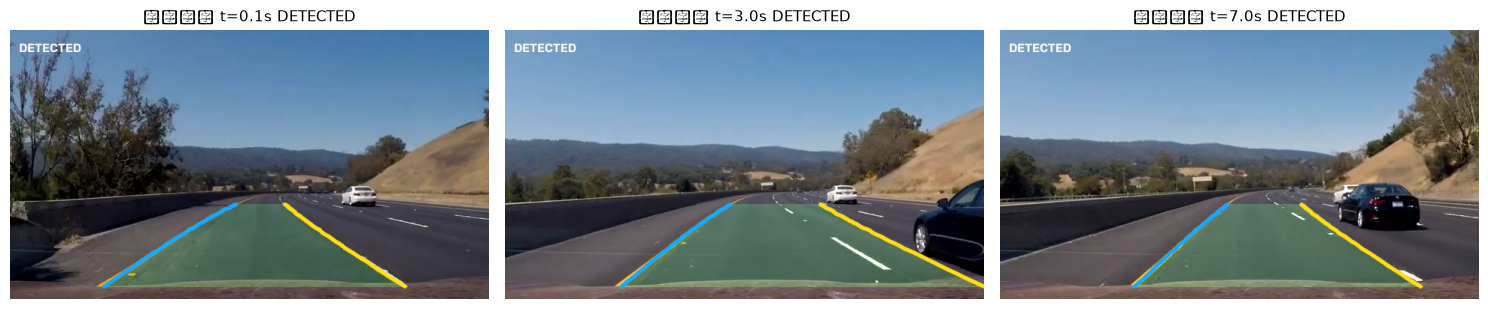

复杂连续弯道: 180 frames; valid 176/180; video E03_complex_compare.mp4


/tmp/ipykernel_2887/2224602797.py:28: UserWarning: Glyph 22797 (\N{CJK UNIFIED IDEOGRAPH-590D}) missing from font(s) DejaVu Sans.
  plt.tight_layout();plt.show()
/tmp/ipykernel_2887/2224602797.py:28: UserWarning: Glyph 26434 (\N{CJK UNIFIED IDEOGRAPH-6742}) missing from font(s) DejaVu Sans.
  plt.tight_layout();plt.show()
/tmp/ipykernel_2887/2224602797.py:28: UserWarning: Glyph 36830 (\N{CJK UNIFIED IDEOGRAPH-8FDE}) missing from font(s) DejaVu Sans.
  plt.tight_layout();plt.show()
/tmp/ipykernel_2887/2224602797.py:28: UserWarning: Glyph 32493 (\N{CJK UNIFIED IDEOGRAPH-7EED}) missing from font(s) DejaVu Sans.
  plt.tight_layout();plt.show()
/opt/hostedtoolcache/Python/3.11.18/x64/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 36830 (\N{CJK UNIFIED IDEOGRAPH-8FDE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/hostedtoolcache/Python/3.11.18/x64/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Gly

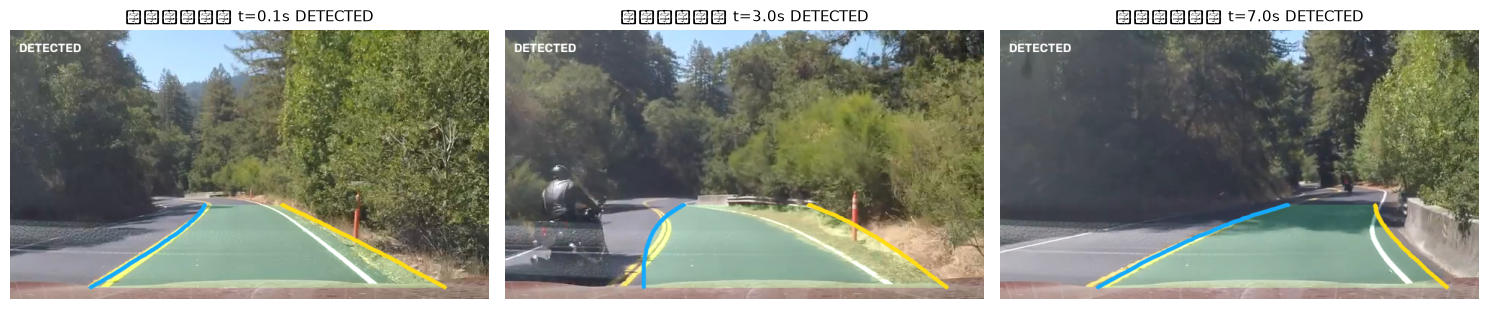

61476

In [10]:
from pathlib import Path
from IPython.display import Video,display
import shutil,subprocess
ffmpeg=shutil.which('ffmpeg')
if not ffmpeg:
    import imageio_ffmpeg
    ffmpeg=imageio_ffmpeg.get_ffmpeg_exe()
summary={}
for scene,label in [('straight','直道'),('curve','普通弯道'),('complex','复杂连续弯道')]:
    cap=cv2.VideoCapture(str(DATA/'videos'/f'E03_{scene}_input.mp4'))
    if not cap.isOpened():raise RuntimeError(f'无法读取 {scene}')
    fps=cap.get(cv2.CAP_PROP_FPS) or 12.
    ok,first=cap.read()
    if not ok:raise RuntimeError('视频为空: '+scene)
    h,w=first.shape[:2]
    rawpath=OUTPUT/f'raw_{scene}.mp4'
    writer=cv2.VideoWriter(str(rawpath),cv2.VideoWriter_fourcc(*'mp4v'),fps,(3*480,270))
    if not writer.isOpened():raise RuntimeError('OpenCV mp4v encoder unavailable')
    cap.set(cv2.CAP_PROP_POS_FRAMES,0)
    track=LaneTracker(alpha=.6,max_missing=3)
    stats=[];saved=[]
    while True:
        ok,frame=cap.read()
        if not ok:break
        raw=resized(frame); old,n,_=e02_hough(raw); new,info,_=e03_detect(raw,scene,tracker=track)
        pieces=[]
        for picture,name in [(raw,'Raw input'),(old,'E02 Canny + Hough'),(new,'E03 curve + EMA')]:
            panel=cv2.resize(picture,(480,270),interpolation=cv2.INTER_AREA)
            cv2.rectangle(panel,(0,0),(480,26),(18,34,48),-1)
            cv2.putText(panel,name,(10,19),cv2.FONT_HERSHEY_SIMPLEX,.55,(255,255,255),1,cv2.LINE_AA)
            pieces.append(panel)
        writer.write(np.hstack(pieces))
        stats.append({'time':round(len(stats)/fps,3),'e02_candidates':n,'valid':bool(info['valid']),
                     'status':info['status'],'x':info['bottom_x']})
        if len(stats) in (1,round(fps*3),round(fps*7)):
            saved.append((f'{label} t={len(stats)/fps:.1f}s {info["status"]}',new.copy()))
    cap.release();writer.release()
    filename=OUTPUT/f'E03_{scene}_compare.mp4'
    subprocess.run([ffmpeg,'-y','-hide_banner','-loglevel','error','-i',str(rawpath),'-an','-c:v','libx264',
                    '-pix_fmt','yuv420p','-preset','veryfast','-crf','27','-movflags','+faststart',str(filename)],check=True)
    rawpath.unlink()
    summary[scene]=stats
    print(f'{label}: {len(stats)} frames; valid {sum(s["valid"] for s in stats)}/{len(stats)}; video {filename.name}')
    panels(saved,cols=3)
    display(Video(filename=str(filename),embed=False,width=720))
(OUTPUT/'E03_diagnostics.json').write_text(__import__('json').dumps(summary,ensure_ascii=False,indent=2),encoding='utf-8')

## 06 · 综合观察与思考
- 哪个场景中 E02 与 E03 的区别最明显？有没有 E03 比 E02 更差的帧？
- 有效帧比例和时序平滑程度，为什么不等于人工 Ground Truth 准确率？
- 有车辆遮挡、标线缺失或道路边线误选时，应继续绘制还是明确报告失效？
- 小结四项探索的适用条件与失败原因。